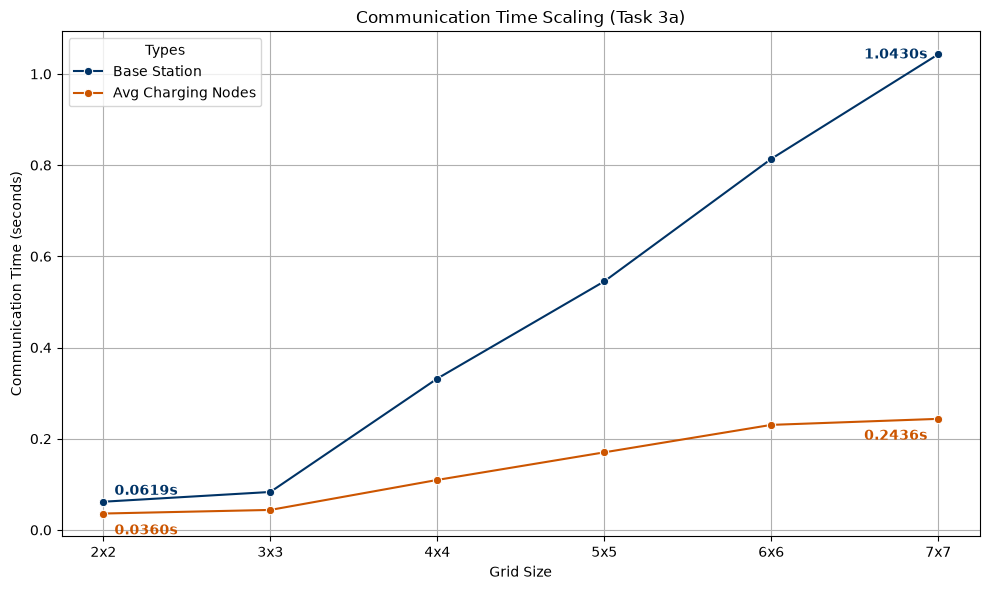

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 读取 Excel 数据
file_path = 'task3a.xlsx'
df = pd.read_excel(file_path)

# 将 'Charging Nodes' 改名为 'Avg Charging Nodes'，并修复可能被截断的 'Base Statio'
df['Types'] = df['Types'].str.replace('Charging Nodes', 'Avg Charging Nodes')

# 设置画布尺寸
plt.figure(figsize=(10, 6))

# 定义深色颜色字典 (深蓝 和 深橙)
types = df['Types'].unique()
colors = ['#003366', '#cc5500'] 
palette = dict(zip(types, colors))

# 绘制折线图
ax = sns.lineplot(data=df, x='Grid Size', y='Communication Time', hue='Types', marker='o', palette=palette)

# 遍历每个类型，为第一个和最后一个数据点添加标签
for t in types:
    subset = df[df['Types'] == t].reset_index(drop=True)
    
    # 获取第一个点 (2x2) 和最后一个点 (7x7)
    first_pt = subset.iloc[0]
    last_pt = subset.iloc[-1]
    
    # 添加第一个点的文字标签 (向右偏移一点，避免盖住数据点)
    ax.annotate(f"{first_pt['Communication Time']:.4f}s",
                xy=(first_pt['Grid Size'], first_pt['Communication Time']),
                xytext=(8, 5 if 'Base' in t else -15), # 基站放上面，节点放下面
                textcoords='offset points',
                color=palette[t],
                fontweight='bold',
                ha='left')
    
    # 添加最后一个点的文字标签
    if 'Base' in t:
        offset = (-8, -3) # 将基站最后一个点的偏移调整为负数，使其处于数据点下方
    else:
        offset = (-8, -15)
        
    ax.annotate(f"{last_pt['Communication Time']:.4f}s",
                xy=(last_pt['Grid Size'], last_pt['Communication Time']),
                xytext=offset,
                textcoords='offset points',
                color=palette[t],
                fontweight='bold',
                ha='right')

# 完善图表信息
plt.title('Communication Time Scaling (Task 3a)')
plt.xlabel('Grid Size')
plt.ylabel('Communication Time (seconds)')
plt.grid(True)
plt.tight_layout()

# 保存图片并展示
# plt.savefig('scaling_plot_dark.png')
plt.show()